In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uncertainties

In [5]:
df = pd.read_csv("run_50K.csv")
df.head()

,V_Copper,V_Sapphire,time,sensor_temperature,temperature_setpoint,iTC_P_param,iTC_I_param,iTC_D_param
0,-0.000009,-0.000002,0.000000,49.9965,50.0,2.0,1.0,0.0
1,-0.000009,-0.000002,0.236099,49.9972,50.0,2.0,1.0,0.0
2,-0.000009,-0.000001,0.458637,49.9972,50.0,2.0,1.0,0.0
3,-0.000009,-0.000001,0.715077,49.9998,50.0,2.0,1.0,0.0
4,-0.000009,-0.000002,0.965157,50.0004,50.0,2.0,1.0,0.0


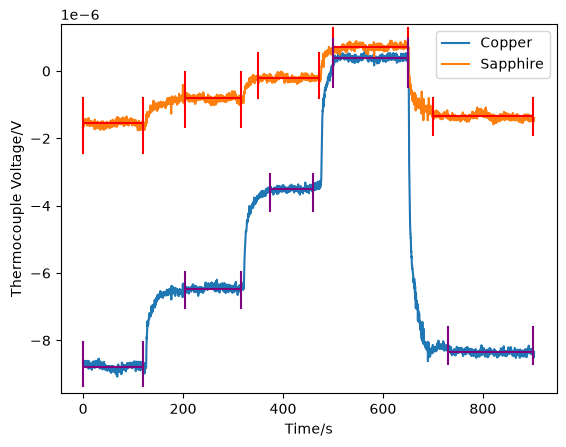

In [ ]:
time = df['time']
v_cop = df['V_Copper']
v_sap = df['V_Sapphire']

plt.plot(time, v_cop, label = 'Copper')
plt.plot(time, v_sap, label = 'Sapphire')
plt.axvline(x = 0 , ymin = 0.65, ymax = 0.8, color = 'r' )
plt.axvline(x = 120 , ymin = 0.65, ymax = 0.8, color = 'r' )
plt.hlines(y = -1.53*1e-6, xmin = 0, xmax = 120, color = 'r')

plt.axvline(x = 203 , ymin = 0.72, ymax = 0.87, color = 'r' )
plt.axvline(x = 315 , ymin = 0.72, ymax = 0.87, color = 'r' )
plt.hlines(y = -0.8*1e-6, xmin = 203, xmax = 315, color = 'r')

plt.axvline(x = 350 , ymin = 0.80, ymax = 0.92, color = 'r' )
plt.axvline(x = 472 , ymin = 0.80, ymax = 0.92, color = 'r' )
plt.hlines(y = -0.2*1e-6, xmin = 350, xmax = 472, color = 'r')

plt.axvline(x = 500 , ymin = 0.87, ymax = 0.99, color = 'r' )
plt.axvline(x = 650 , ymin = 0.87, ymax = 0.99, color = 'r' )
plt.hlines(y = 0.7*1e-6, xmin = 500 , xmax = 650, color = 'r')

plt.axvline(x = 700 , ymin = 0.70, ymax = 0.80, color = 'r' )
plt.axvline(x = 900 , ymin = 0.70, ymax = 0.80, color = 'r' )
plt.hlines(y = -1.33*1e-6, xmin = 700 , xmax = 900, color = 'r')


plt.axvline(x = 0 , ymin = 0.02, ymax = 0.14, color = 'purple' )
plt.axvline(x = 120 , ymin = 0.02, ymax = 0.14, color = 'purple' )
plt.hlines(y = -8.78*1e-6, xmin = 0 , xmax = 120, color = 'purple')

plt.axvline(x = 203 , ymin = 0.23, ymax = 0.33, color = 'purple' )
plt.axvline(x = 315 , ymin = 0.23, ymax = 0.33, color = 'purple' )
plt.hlines(y = -6.48*1e-6, xmin = 203 , xmax = 315, color = 'purple')

plt.axvline(x = 374, ymin = 0.495, ymax = 0.595, color = 'purple' )
plt.axvline(x = 460 , ymin = 0.495, ymax = 0.595, color = 'purple' )
plt.hlines(y = -3.5*1e-6, xmin = 374 , xmax = 460, color = 'purple')

plt.axvline(x = 500 , ymin = 0.83, ymax = 0.96, color = 'purple' )
plt.axvline(x = 650 , ymin = 0.83, ymax = 0.96, color = 'purple' )
plt.hlines(y = 0.40*1e-6, xmin = 500 , xmax = 650, color = 'purple')

plt.axvline(x = 730 , ymin = 0.08, ymax = 0.18, color = 'purple' )
plt.axvline(x = 900 , ymin = 0.08, ymax = 0.18, color = 'purple' )
plt.hlines(y = -8.355*1e-6, xmin = 730 , xmax = 900, color = 'purple')



plt.legend()
plt.title('Thermocouple Voltage VS ')
plt.xlabel("Time/s")
plt.ylabel("Thermocouple Voltage/V")
plt.show()

In [148]:
windows15K = {
    "V_Copper":   [(0, 118), (155, 228), (260, 395), (440, 612), (660, 770)],
    "V_Sapphire": [(0, 118), (145, 228), (255, 395), (425, 612), (660, 770)],
}

windows20K = {
    "V_Copper":   [(0, 105), (175, 238), (285, 365), (420, 498), (630, 670)],
    "V_Sapphire": [(0, 105), (140, 238), (270, 365), (390, 498), (620, 670)],
}

windows30K = {
    "V_Copper":   [(0, 115), (200, 292), (340, 430), (500, 670), (725, 855)],
    "V_Sapphire": [(0, 115), (190, 292), (330, 430), (500, 670), (725, 855)],
}

windows40K = {
    "V_Copper":   [(0, 110), (175, 262), (320, 415), (520, 715), (800, 970)],
    "V_Sapphire": [(0, 110), (170, 255), (300, 450), (510, 715), (860, 970)],
}

windows50K = { 
    "V_Copper":   [(0, 120), (203, 315), (350, 472), (500, 650), (730, 900)],
    "V_Sapphire": [(0, 120), (203, 315), (374, 460), (500, 600), (730, 900)],
}

windows = windows50K

v_avg = {}
v_std = {}

for material, times in windows.items():
    print(material)
    v_avg[material] = []
    v_std[material] = []
    for start, end in times:
        in_window = (time >= start) & (time <= end)
        average = df.loc[in_window, material].mean()
        std = df.loc[in_window, material].std()
        v_avg[material].append(average)
        v_std[material].append(std)
        print(f"  {start}-{end} s: {average:.4e} +- {std:.4e} V")

V_Copper
  0-120 s: -8.7689e-06 +- 8.5776e-08 V
  203-315 s: -6.4470e-06 +- 7.0912e-08 V
  350-472 s: -3.5227e-06 +- 8.1531e-08 V
  500-650 s: 3.9175e-07 +- 6.8037e-08 V
  730-900 s: -8.3439e-06 +- 6.7097e-08 V
V_Sapphire
  0-120 s: -1.5605e-06 +- 7.7909e-08 V
  203-315 s: -8.1101e-07 +- 6.9537e-08 V
  374-460 s: -2.1061e-07 +- 6.9131e-08 V
  500-600 s: 6.9766e-07 +- 7.7947e-08 V
  730-900 s: -1.3644e-06 +- 7.7213e-08 V


In [149]:
baseline = {
    "V_Copper": v_avg["V_Copper"][0],
    "V_Sapphire": v_avg["V_Sapphire"][0]
}

v_avg_adj = {}

for material in v_avg.keys():
    v_avg_adj[material] = []
    #print(material)
    for i in range(1, len(v_avg[material])-1):
        v_avg_adj[material].append(v_avg[material][i]-baseline[material])
for material, values in v_avg_adj.items():
    print(material)
    output = "[0,"
    std_output = f"[{v_std[material][0]},"
    for i, v in enumerate(values, start=1):
        #print(f"  Step {i}: {v:.4e} V")
        output = output + f"{v}"
        std_output = std_output + f"{v_std[material][i-1]}"
        if i != len(values):
            output = output+","
            std_output = std_output+","
    output = output + "]"
    std_output = std_output + "]"
    print(output)
    print(std_output)

V_Copper
[0,2.321886901609156e-06,5.246242725599814e-06,9.160680386935391e-06]
[8.5775678129242e-08,8.5775678129242e-08,7.091151682685826e-08,8.15310008796889e-08]
V_Sapphire
[0,7.495118386254181e-07,1.3499106788707363e-06,2.258185347484277e-06]
[7.790927032271659e-08,7.790927032271659e-08,6.953745195624841e-08,6.913076879798453e-08]
